# 01. Data audit

Check the news timestamps, ticker coverage and duplicates **before** trusting any result. Set `CONFIG` to `configs/default.yaml` to audit the real FNSPID files; the default runs on the synthetic world.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from newsgate.config import load_config
from newsgate.data import build_sources, TradingCalendar, assign_feature_dates, deduplicate_news

CONFIG = 'configs/synthetic.yaml'
cfg = load_config(CONFIG)
sources = build_sources(cfg.data)
news = sources.news.load()
prices = sources.prices.load(sources.tickers)
len(news), len(prices)

(62499, 35000)

## 1. Do the timestamps carry a time of day?

This decides whether articles can be placed before or after the 4:00 pm close. If almost nothing has a time, the conservative date-only rule applies (use news from day *t* only for day *t+1* onward).

share with a time of day: 1.0


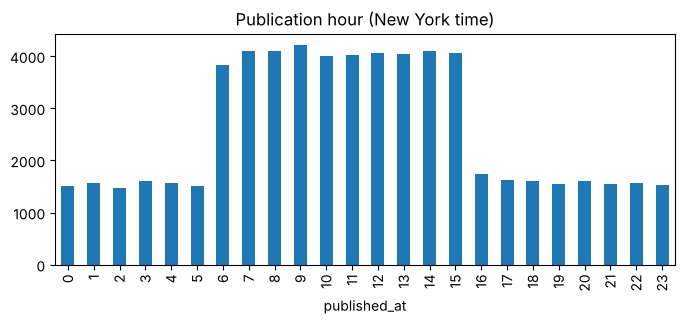

In [2]:
print('share with a time of day:', round(news['has_time'].mean(), 3))
ny = pd.to_datetime(news.loc[news['has_time'], 'published_at']).dt.tz_localize('UTC').dt.tz_convert('America/New_York')
ny.dt.hour.value_counts().sort_index().plot(kind='bar', title='Publication hour (New York time)', figsize=(8, 3))
plt.show()

## 2. How many articles survive cleaning and alignment?

In [3]:
cal = TradingCalendar.from_prices(prices)
cleaned = deduplicate_news(news)
aligned = assign_feature_dates(cleaned, cal)
pd.Series({'raw': len(news), 'after dedup': len(cleaned), 'aligned to a trading day': len(aligned)})

raw                         62499
after dedup                 51280
aligned to a trading day    51276
dtype: int64

In [4]:
after_close = aligned['published_at'].dt.normalize() != aligned['feature_date']
print('articles moved to a later trading day:', round(after_close.mean(), 3))

articles moved to a later trading day: 0.117


## 3. Coverage per ticker (articles per trading day)

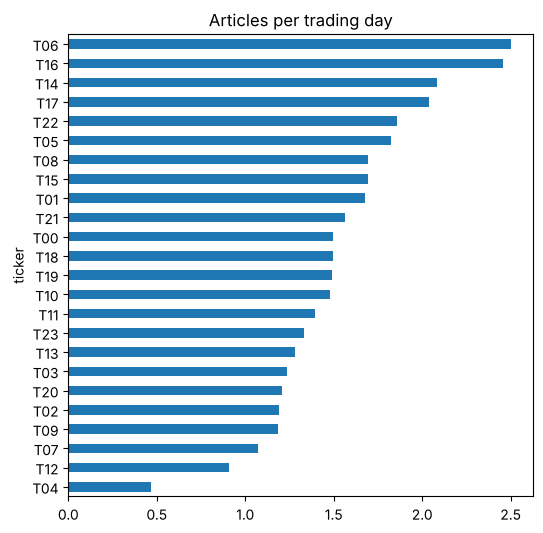

count    24.000000
mean      1.526071
std       0.462223
min       0.468571
25%       1.228929
50%       1.493929
75%       1.727143
max       2.502857
dtype: float64

In [5]:
per_ticker = aligned.groupby('ticker').size() / len(cal)
per_ticker.sort_values().plot(kind='barh', figsize=(6, 6), title='Articles per trading day')
plt.show()
per_ticker.describe()

## 4. Coverage drift over time

A rising or falling number of articles per year can create spurious signals.

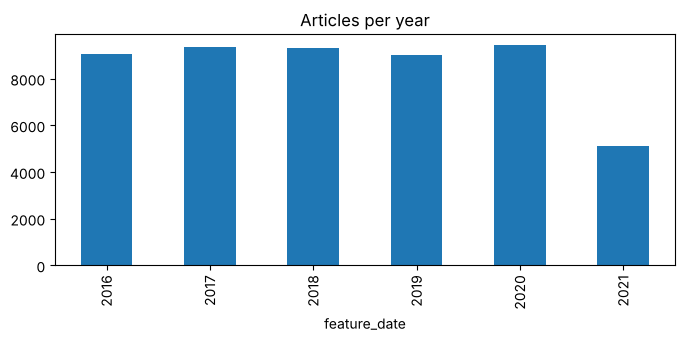

In [6]:
aligned.groupby(aligned['feature_date'].dt.year).size().plot(kind='bar', title='Articles per year', figsize=(8, 3))
plt.show()